[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/MFM/blob/main/Quantlets/Ch_20/MFM_ch20_leadlag/MFM_ch20_leadlag.ipynb)

# MFM_ch20_leadlag

Signature lead-lag metric of Bennett, Cucuringu and Reinert (2022, Machine Learning) on intraday paths: five-minute bars of SPY and Bitcoin in the US session, cross-correlations by lag and the Newey-West t-statistic of the mean daily Levy area for windows from 10 minutes to the whole session.

*Modelling Financial Markets (MFM), Daniel Traian Pele, Bucharest University of Economic Studies*

Paper: Bennett, S., Cucuringu, M., Reinert, G. (2022). Lead-lag detection and network clustering for multivariate time series with an application to the US equity market. *Machine Learning*, 111(12), 4497-4538. https://doi.org/10.1007/s10994-022-06250-4

Data: five-minute bars of SPY and BTC-USD (EODHD), saved in the course repository under `data/market/intraday`.

> **Working in Google Colab? Save your own copy first.**
> The Colab link opens a temporary copy: when you close the tab or the session times out, your changes are lost.
> Use **File → Save a copy in Drive** (it goes to the *Colab Notebooks* folder of your ASE Google Drive) and work in that copy.
> For the team project, **File → Save a copy in GitHub** puts the notebook directly in your team's repository.
> Files you create while the notebook runs (CSV, charts) are also temporary: set `SAVE_TO_DRIVE = True` in the next cell to keep them.

In [1]:
# Optional (Colab only): keep the files you create in Google Drive
SAVE_TO_DRIVE = False   # set to True, run this cell and allow access to your Drive

import os
OUT_DIR = '.'
if SAVE_TO_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    OUT_DIR = '/content/drive/MyDrive/MFM/Chapter_20'
    os.makedirs(OUT_DIR, exist_ok=True)
print('Save your outputs to:', os.path.abspath(OUT_DIR))


Save your outputs to: /Users/danpele/Documents/2026 MFM/MFM/Quantlets/Ch_20/MFM_ch20_leadlag


In [2]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')


## Data: five-minute bars of SPY and Bitcoin

In [3]:
REPO_RAW = 'https://raw.githubusercontent.com/danpele/MFM/main/data/market/intraday/'
# local copy of data/market/intraday when the notebook runs inside the repository
INTRA = next((os.path.join(d, 'data', 'market', 'intraday') for d in ('.', '..', '../..', '../../..')
              if os.path.isdir(os.path.join(d, 'data', 'market', 'intraday'))), '')
FILES = {'spy': 'SPY.US_5m.csv', 'btc': 'BTC-USD.CC_5m.csv'}
LAGS = list(range(-6, 7))
WINDOWS = [2, 3, 4, 6, 12, 24, 39, 78]   # five-minute steps: 10 minutes ... the whole session (78 steps)
MIN_BARS = 70                            # common bars needed for a day to count (a full session has 79)


def read_bars(f):
    path = os.path.join(INTRA, f) if INTRA else REPO_RAW + f
    d = pd.read_csv(path, parse_dates=['datetime_utc']).set_index('datetime_utc')
    return np.log(d['close'])


def load_days():
    """Per-day arrays (n x 2) of SPY and BTC five-minute log returns, each divided by its standard deviation."""
    df = pd.concat({k: read_bars(f) for k, f in FILES.items()}, axis=1, join='inner').dropna()
    days, dates = [], []
    for day, g in df.groupby(df.index.date):
        if len(g) < MIN_BARS:
            continue
        r = np.diff(g[['spy', 'btc']].values, axis=0)
        days.append(r / r.std(axis=0))
        dates.append(pd.Timestamp(day))
    return days, dates


days, dates = load_days()
print(len(days), 'common trading days,', dates[0].date(), 'to', dates[-1].date())


494 common trading days, 2024-09-03 to 2026-09-18


## The signature lead-lag metric

For two normalised log-price paths $X^i, X^j$ on $[t-m, t]$, Bennett, Cucuringu and Reinert (2022) use
$$S^{ij} = \iint_{t-m<u<v<t} \big(dX^i_u\, dX^j_v - dX^j_u\, dX^i_v\big) = 2A^{ij},$$
twice the Lévy area (the antisymmetric part of level 2 of the signature). For a piecewise-linear path through $m+1$ points with increments $x_i$ (SPY) and $y_i$ (BTC),
$$A_m = \tfrac12 \sum_{l=1}^{m-1} \sum_i \big(x_i\, y_{i+l} - y_i\, x_{i+l}\big):$$
lag $l$ enters $m-l$ times. The daily statistic is the mean area over all windows of $m$ steps in the day; the test is a Newey-West $t$-statistic over days.

In [4]:
def cross_corr(r, l):
    """corr(SPY_{t-l}, BTC_t): positive l = SPY moves first."""
    x, y = r[:, 0], r[:, 1]
    if l > 0:
        return np.corrcoef(x[:-l], y[l:])[0, 1]
    if l < 0:
        return np.corrcoef(x[-l:], y[:l])[0, 1]
    return np.corrcoef(x, y)[0, 1]


def window_area(r, m):
    """Mean Levy area of the path (cumulative normalised returns) over all rolling windows of m steps in the day."""
    X = np.vstack([np.zeros(2), np.cumsum(r, axis=0)])
    m = min(m, len(r))                       # the last window (78 steps) is the whole session
    a = []
    for i in range(len(r) - m + 1):
        P = X[i:i + m + 1] - X[i]
        x, y = P[:, 0], P[:, 1]
        a.append(0.5 * np.sum(x[:-1] * np.diff(y) - y[:-1] * np.diff(x)))
    return float(np.mean(a))


def nw_var(d, lag):
    """Newey-West (Bartlett) long-run variance of a series."""
    d = np.asarray(d, float) - np.mean(d)
    T = len(d)
    v = d @ d / T
    for j in range(1, lag + 1):
        v += 2 * (1 - j / (lag + 1)) * (d[j:] @ d[:-j]) / T
    return v


def nw_t(v):
    v = np.asarray(v, float)
    T = len(v)
    lag = int(max(1, np.ceil(T ** (1 / 3))))
    return float(v.mean() / np.sqrt(nw_var(v, lag) / T))


C = np.array([[cross_corr(r, l) for l in LAGS] for r in days])
A = np.array([[window_area(r, m) for m in WINDOWS] for r in days])
T = len(days)
ccf_mean, ccf_se = C.mean(axis=0), C.std(axis=0, ddof=1) / np.sqrt(T)
res = {'n_days': T,
       'ccf': {l: (round(float(ccf_mean[j]), 4), round(nw_t(C[:, j]), 2)) for j, l in enumerate(LAGS)},
       'area': {m: dict(t=round(nw_t(A[:, j]), 2), share_pos=round(float((A[:, j] > 0).mean()), 3))
                for j, m in enumerate(WINDOWS)},
       'lag1_by_year': {y: round(float(C[[d.year == y for d in dates], LAGS.index(1)].mean()), 3)
                        for y in sorted({d.year for d in dates})}}
print(json.dumps(res, indent=1, default=str))


{
 "n_days": 494,
 "ccf": {
  "-6": [
   -0.0012,
   -0.23
  ],
  "-5": [
   -0.0108,
   -1.92
  ],
  "-4": [
   0.0033,
   0.45
  ],
  "-3": [
   0.0008,
   0.15
  ],
  "-2": [
   0.0005,
   0.08
  ],
  "-1": [
   -0.0064,
   -0.97
  ],
  "0": [
   0.4049,
   32.9
  ],
  "1": [
   0.0909,
   10.04
  ],
  "2": [
   -0.0113,
   -2.23
  ],
  "3": [
   -0.0137,
   -2.31
  ],
  "4": [
   -0.0046,
   -0.76
  ],
  "5": [
   -0.0154,
   -2.49
  ],
  "6": [
   -0.0095,
   -1.84
  ]
 },
 "area": {
  "2": {
   "t": 10.05,
   "share_pos": 0.713
  },
  "3": {
   "t": 8.53,
   "share_pos": 0.674
  },
  "4": {
   "t": 7.43,
   "share_pos": 0.632
  },
  "6": {
   "t": 6.42,
   "share_pos": 0.617
  },
  "12": {
   "t": 4.85,
   "share_pos": 0.589
  },
  "24": {
   "t": 3.17,
   "share_pos": 0.561
  },
  "39": {
   "t": 2.47,
   "share_pos": 0.555
  },
  "78": {
   "t": 1.05,
   "share_pos": 0.51
  }
 },
 "lag1_by_year": {
  "2024": 0.103,
  "2025": 0.125,
  "2026": 0.04
 }
}


## Chart: cross-correlations by lag and the signature metric by window length

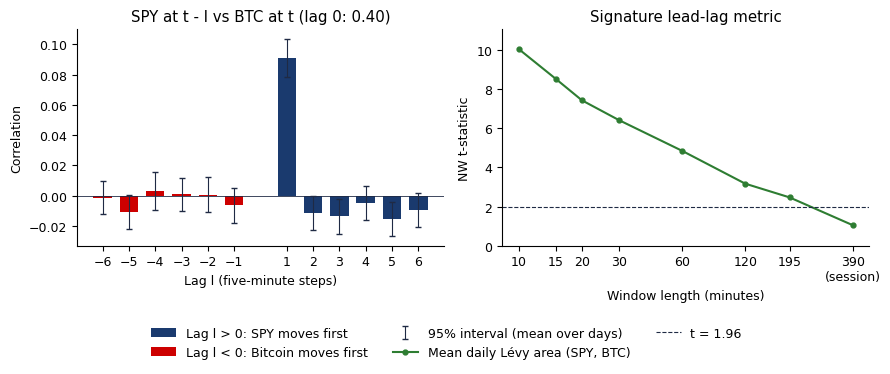

In [5]:
# MFM style: transparent background, English labels, legend below the plot
plt.rcParams.update({'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none',
                     'savefig.transparent': True, 'axes.grid': False, 'font.size': 9,
                     'axes.spines.top': False, 'axes.spines.right': False, 'legend.frameon': False})
MainBlue, IDAred, Forest, Navy = '#1A3A6E', '#CD0000', '#2E7D32', '#1F2A44'

fig, (a1, a2) = plt.subplots(1, 2, figsize=(9, 3.2))
L = np.array(LAGS)
k, pos, neg = L != 0, L > 0, L < 0
a1.bar(L[pos], ccf_mean[pos], color=MainBlue, width=0.7, label='Lag l > 0: SPY moves first')
a1.bar(L[neg], ccf_mean[neg], color=IDAred, width=0.7, label='Lag l < 0: Bitcoin moves first')
a1.errorbar(L[k], ccf_mean[k], yerr=1.96 * ccf_se[k], fmt='none', ecolor=Navy, elinewidth=0.8, capsize=2,
            label='95% interval (mean over days)')
a1.axhline(0, color=Navy, lw=0.6)
a1.set_xticks(L[k])
a1.set_xlabel('Lag l (five-minute steps)')
a1.set_ylabel('Correlation')
a1.set_title(f'SPY at t - l vs BTC at t (lag 0: {ccf_mean[LAGS.index(0)]:.2f})')
W = np.array(WINDOWS)
t = np.array([res['area'][m]['t'] for m in WINDOWS])
a2.plot(W * 5, t, '-o', color=Forest, ms=3.5, label='Mean daily Lévy area (SPY, BTC)')
a2.axhline(1.96, color=Navy, ls='--', lw=0.8, label='t = 1.96')
a2.set_xscale('log')
a2.set_xticks(W * 5)
a2.set_xticklabels([f'{5 * m}' for m in W[:-1]] + ['390\n(session)'])
a2.minorticks_off()
a2.set_xlabel('Window length (minutes)')
a2.set_ylabel('NW t-statistic')
a2.set_ylim(0, max(t) * 1.1)
a2.set_title('Signature lead-lag metric')
h, lab = [], []
for ax in (a1, a2):
    for hh, ll in zip(*ax.get_legend_handles_labels()):
        h.append(hh)
        lab.append(ll)
fig.legend(h, lab, loc='upper center', bbox_to_anchor=(0.5, 0.0), ncol=3, frameon=False)
fig.tight_layout()
for ext in ('pdf', 'png'):
    fig.savefig(os.path.join(OUT_DIR, f'ch20_leadlag.{ext}'), bbox_inches='tight', transparent=True, dpi=180)
plt.show()


![ch20_leadlag](./ch20_leadlag.png)

Output: `ch20_leadlag.pdf`